# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [2]:
df = pd.read_csv("Salary_Data.csv")
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [3]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isna().sum())

df.describe()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [4]:
X = df[["YearsExperience"]]
y = df["Salary"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 25321.583011776813
Coefficient: 9423.815323030976


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [7]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

,YearsExperience,ActualSalary,PredictedSalary
0,9.6,112635.0,115790.210113
1,4.9,67938.0,71498.278095
2,8.2,113812.0,102596.868661
3,5.3,83088.0,75267.804224
4,3.2,64445.0,55477.792045


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 6286.453830757749
MSE : 49830096.85590839
RMSE: 7059.04362190151
R^2 : 0.9024461774180497


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

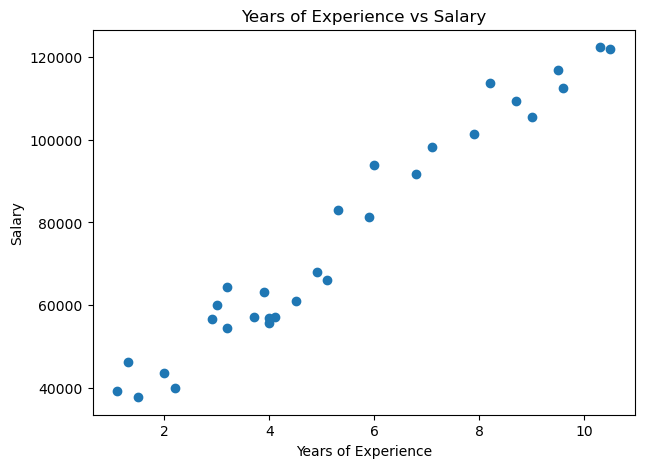

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(df["YearsExperience"], df["Salary"])
plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

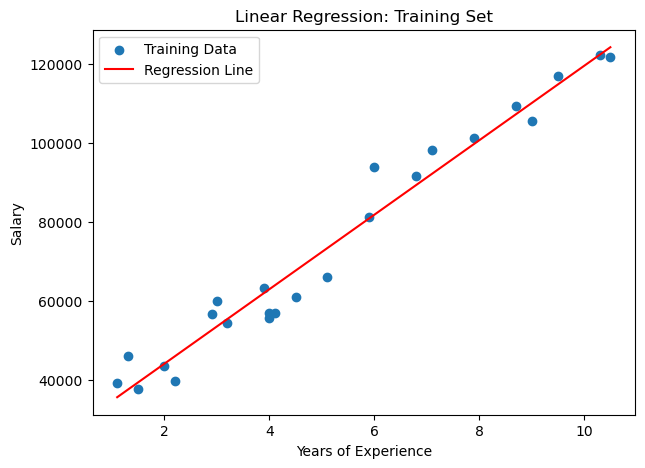

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(
    X_train["YearsExperience"],
    y_train,
    label="Training Data"
)

X_train_line = X_train.sort_values(by="YearsExperience")
y_train_line = model.predict(X_train_line)

plt.plot(
    X_train_line["YearsExperience"],
    y_train_line,
    color="red",
    label="Regression Line"
)

plt.title("Linear Regression: Training Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

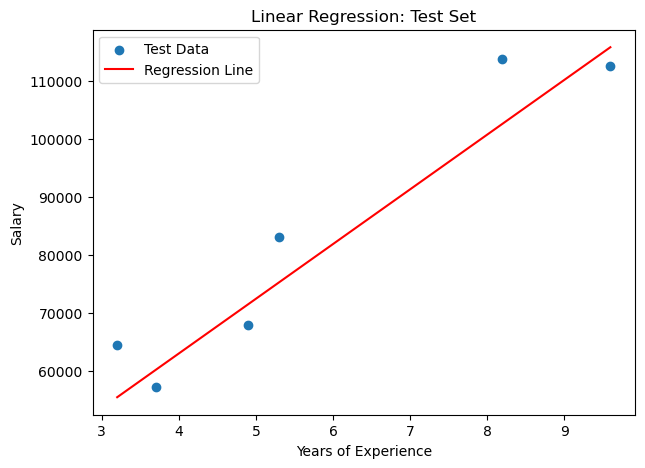

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(
    X_test["YearsExperience"],
    y_test,
    label="Test Data"
)

X_line = X_test.sort_values(by="YearsExperience")
y_line = model.predict(X_line)

plt.plot(
    X_line["YearsExperience"],
    y_line,
    color="red",
    label="Regression Line"
)

plt.title("Linear Regression: Test Set")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

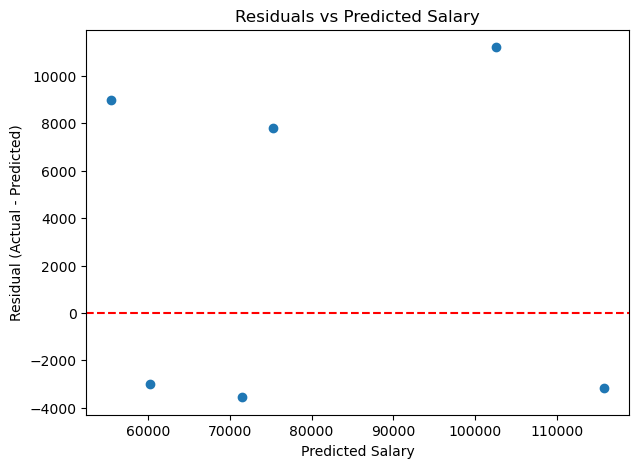

In [12]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs Predicted Salary")
plt.xlabel("Predicted Salary")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [13]:
# Exercise A:
# The slope is the predicted increase in salary for each additional
# year of experience.

# Exercise B:
# A high R² means the model explains a large proportion of the
# variation in salary in the evaluated data. It does not prove
# that experience causes the salary differences.

# Exercise C:
# Outliers can pull the regression line toward them, changing
# its slope and intercept and making other predictions less accurate.

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [15]:
# Change the test size from 20% to 30%.
X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

model_ext = LinearRegression()
model_ext.fit(X_train_ext, y_train_ext)

y_pred_ext = model_ext.predict(X_test_ext)

mae_ext = mean_absolute_error(y_test_ext, y_pred_ext)
mse_ext = mean_squared_error(y_test_ext, y_pred_ext)
rmse_ext = np.sqrt(mse_ext)
r2_ext = r2_score(y_test_ext, y_pred_ext)

comparison = pd.DataFrame({
    "Test Size": [0.2, 0.3],
    "Training Rows": [len(X_train), len(X_train_ext)],
    "Test Rows": [len(X_test), len(X_test_ext)],
    "MAE": [mae, mae_ext],
    "MSE": [mse, mse_ext],
    "RMSE": [rmse, rmse_ext],
    "R²": [r2, r2_ext]
})

print(comparison.to_string(index=False))

print("\nConclusion:")
print(
    f"With a 30% test set, the model used {len(X_train_ext)} training "
    f"rows instead of {len(X_train)}, and {len(X_test_ext)} test rows "
    f"instead of {len(X_test)}."
)
print(
    f"RMSE changed from {rmse:.2f} to {rmse_ext:.2f}, "
    f"and R² changed from {r2:.4f} to {r2_ext:.4f}."
)
print(
    "The scores depend on the split, so this comparison alone "
    "does not show that one test size is always better."
)

 Test Size  Training Rows  Test Rows         MAE          MSE        RMSE       R²
       0.2             24          6 6286.453831 4.983010e+07 7059.043622 0.902446
       0.3             21          9 5161.328710 3.778466e+07 6146.923008 0.941447

Conclusion:
With a 30% test set, the model used 21 training rows instead of 24, and 9 test rows instead of 6.
RMSE changed from 7059.04 to 6146.92, and R² changed from 0.9024 to 0.9414.
The scores depend on the split, so this comparison alone does not show that one test size is always better.
